# HDI Group Classification

Predicts which UNDP human development group a country belongs to (Low, Medium, High or Very High) from four indicators: life expectancy, expected years of schooling, GNI per capita and income inequality.

**Data:** UNDP "Human Development Index - Full" file (Human Development Reports, hdr.undp.org). Save it as `Human_Development_Index_-_Full.csv` in the same folder as this notebook to run it.

The charts below are saved from my project run. The HDI score and mean years of schooling are not used as features, because the group is defined from the HDI score and using it would leak the answer.

## Step 1: Load and inspect the data

In [ ]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import warnings; warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

raw = pd.read_csv("Human_Development_Index_-_Full.csv")
print(raw.shape)                       # (rows, columns)
print(raw.iloc[:, :5].head())          # identifier columns
print(raw["Human Development Groups"].value_counts(dropna=False))

In [ ]:
# every other column is "<indicator> (<year>)"; count the distinct indicators
indicators = sorted({c.rsplit(" (", 1)[0] for c in raw.columns[5:]})
print(len(indicators), "indicators, e.g.:")
for ind in indicators[:6]:
    print(" -", ind)

In [ ]:
cols = {"Country": "Country",
        "Human Development Groups": "HDI_Group",
        "Human Development Index (2021)": "HDI",
        "Life Expectancy at Birth (2021)": "Life_Expectancy",
        "Expected Years of Schooling (2021)": "Expected_Schooling",
        "Gross National Income Per Capita (2021)": "GNI_per_Capita",
        "Inequality in income (2021)": "Income_Inequality"}
d0 = raw[list(cols)].rename(columns=cols)
print(d0.shape)
print(d0.dtypes)
print(d0.head())
print(d0.isna().sum())
print(d0.describe().T.round(2))

## Step 2: Clean the data
Drop the 36 countries with missing values, leaving 159.

In [ ]:
df = d0.dropna().reset_index(drop=True)
print(d0.shape, "->", df.shape)
print("Duplicates:", df.duplicated().sum())
print("Missing :", df.isna().sum().sum())
print()
print("Rows removed, by HDI group:")
print(d0[d0.isna().any(axis=1)]["HDI_Group"].value_counts(dropna=False))

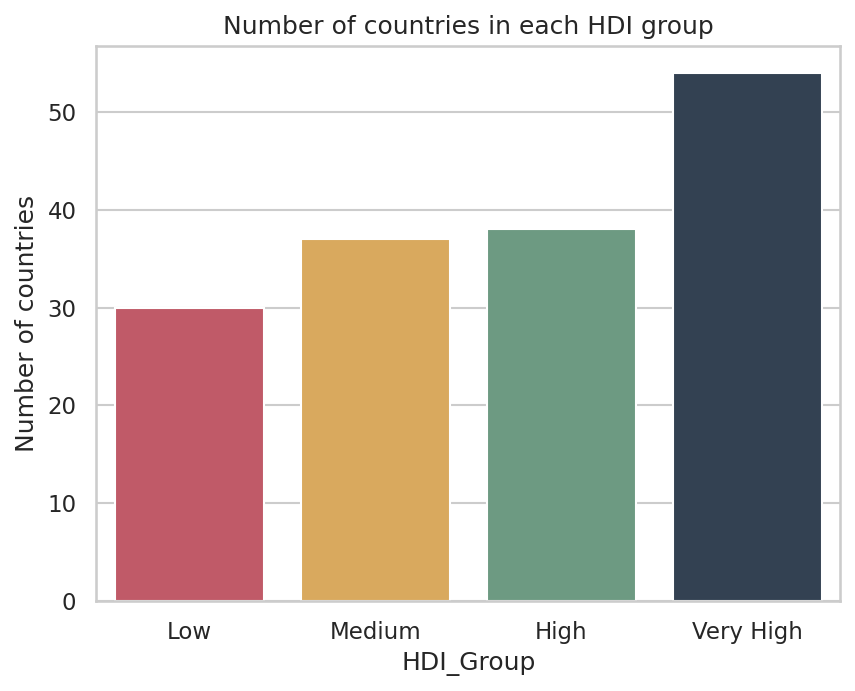

In [ ]:
order = ["Low", "Medium", "High", "Very High"]
palette = {"Low": "#d1495b", "Medium": "#edae49", "High": "#66a182", "Very High": "#2e4057"}
feat = ["Life_Expectancy", "Expected_Schooling", "GNI_per_Capita", "Income_Inequality"]
print(df["HDI_Group"].value_counts().reindex(order))
print((df["HDI_Group"].value_counts(normalize=True).reindex(order) * 100).round(1))
print(df.groupby("HDI_Group")["HDI"].agg(["min", "max"]).reindex(order))
counts = df["HDI_Group"].value_counts().reindex(order)
sns.barplot(x=counts.index, y=counts.values, palette=palette, order=order)
plt.ylabel("Number of countries"); plt.title("Number of countries in each HDI group")
plt.show()

## Step 3: Explore the data

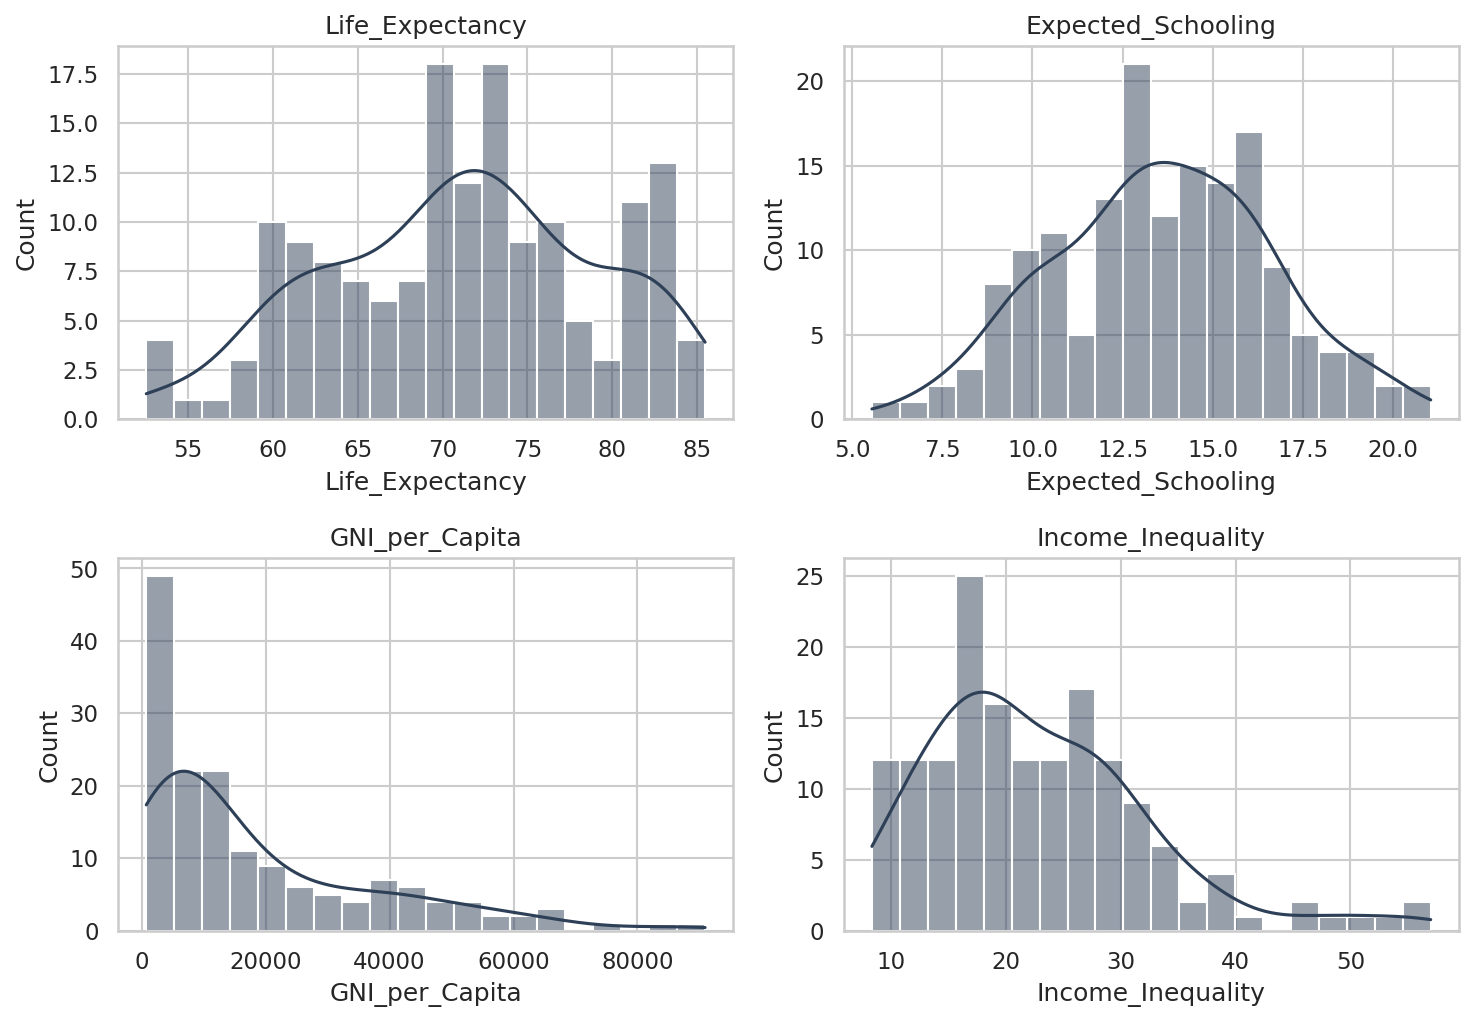

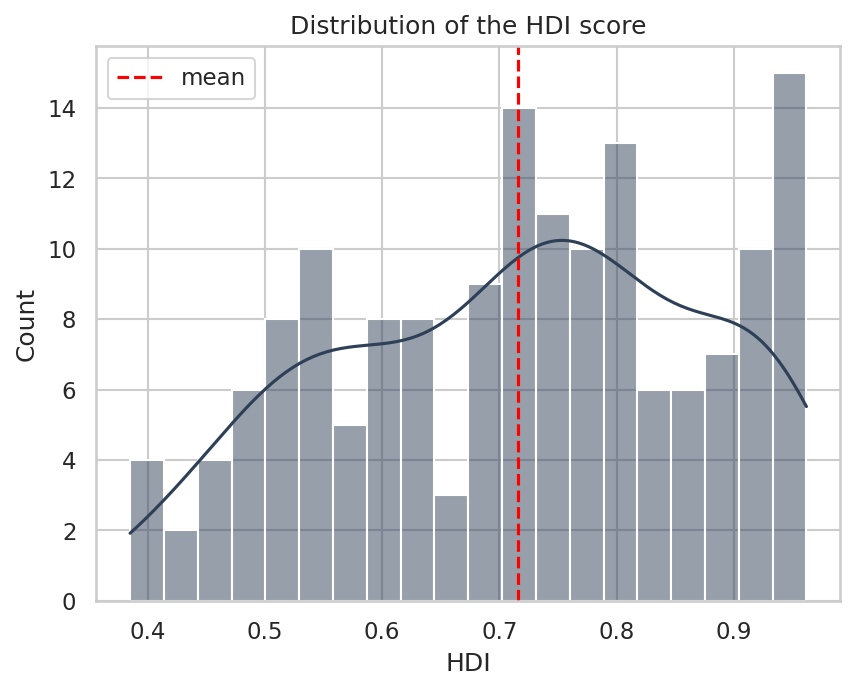

In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(10, 7))
for a, c in zip(ax.flatten(), feat):
    sns.histplot(df[c], bins=20, kde=True, ax=a, color="#2e4057")
    a.set_title(c)
plt.tight_layout(); plt.show()

sns.histplot(df["HDI"], bins=20, kde=True, color="#2e4057")
plt.axvline(df["HDI"].mean(), color="red", ls="--", label="mean")
plt.legend(); plt.title("Distribution of the HDI score"); plt.show()

print(df[["HDI"] + feat].skew().round(2))

In [ ]:
g = df.groupby("HDI_Group")[feat]
print("MEAN"); print(g.mean().reindex(order).round(1))
print("\nSTD"); print(g.std().reindex(order).round(1))
print("\nMEDIAN"); print(g.median().reindex(order).round(1))

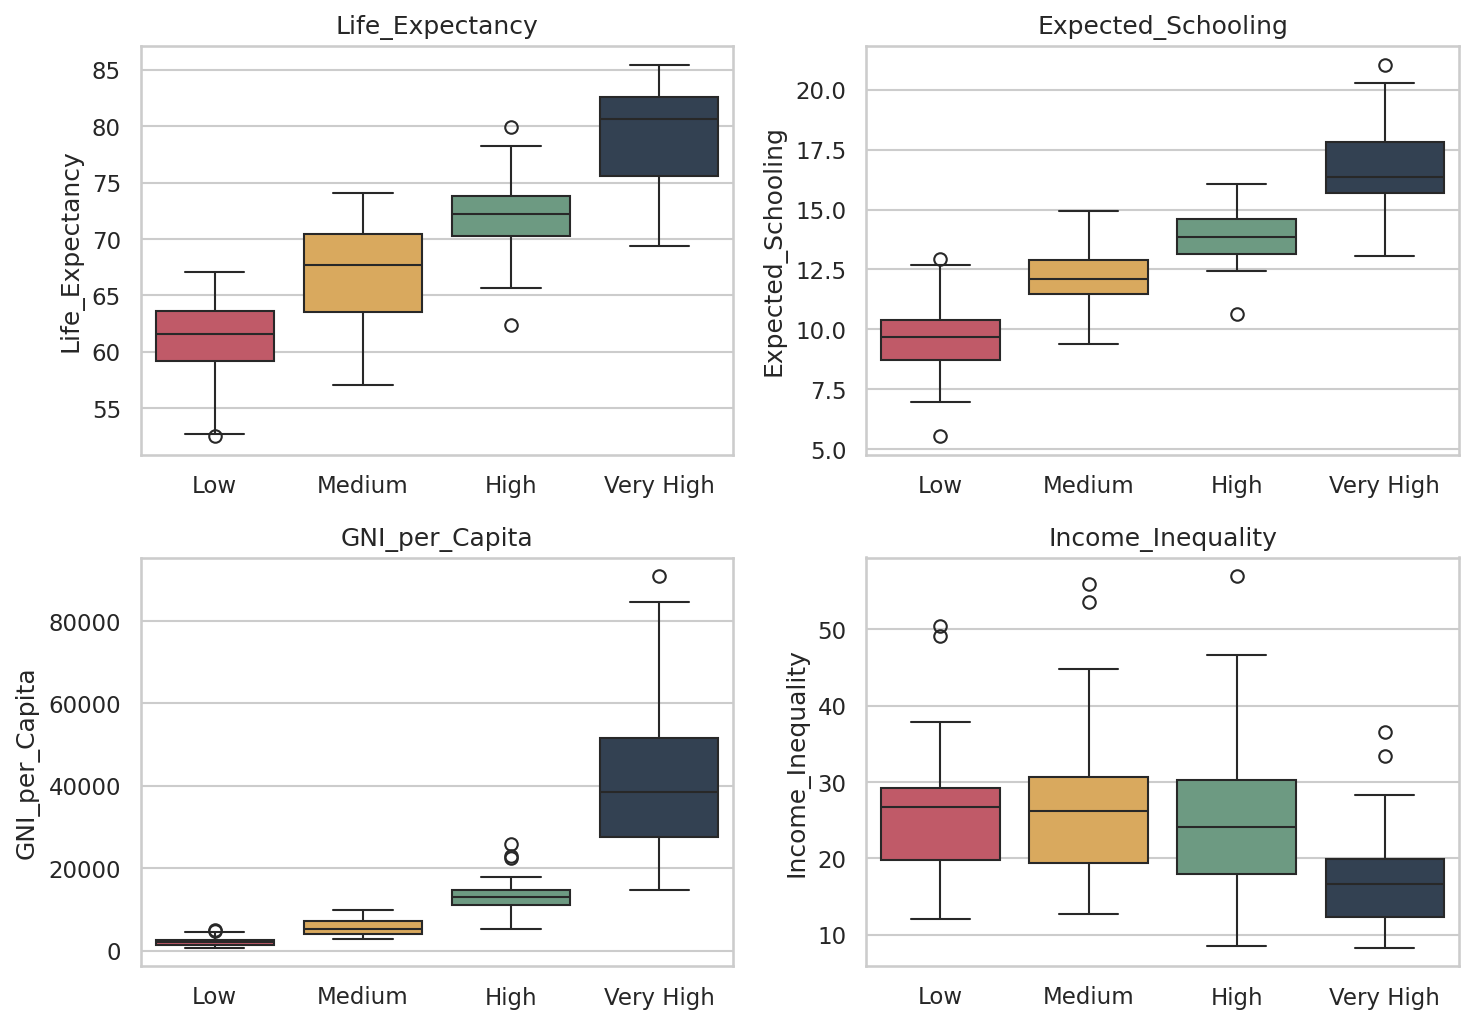

In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(10, 7))
for a, c in zip(ax.flatten(), feat):
    sns.boxplot(data=df, x="HDI_Group", y=c, order=order, palette=palette, ax=a)
    a.set_xlabel(""); a.set_title(c)
plt.tight_layout(); plt.show()

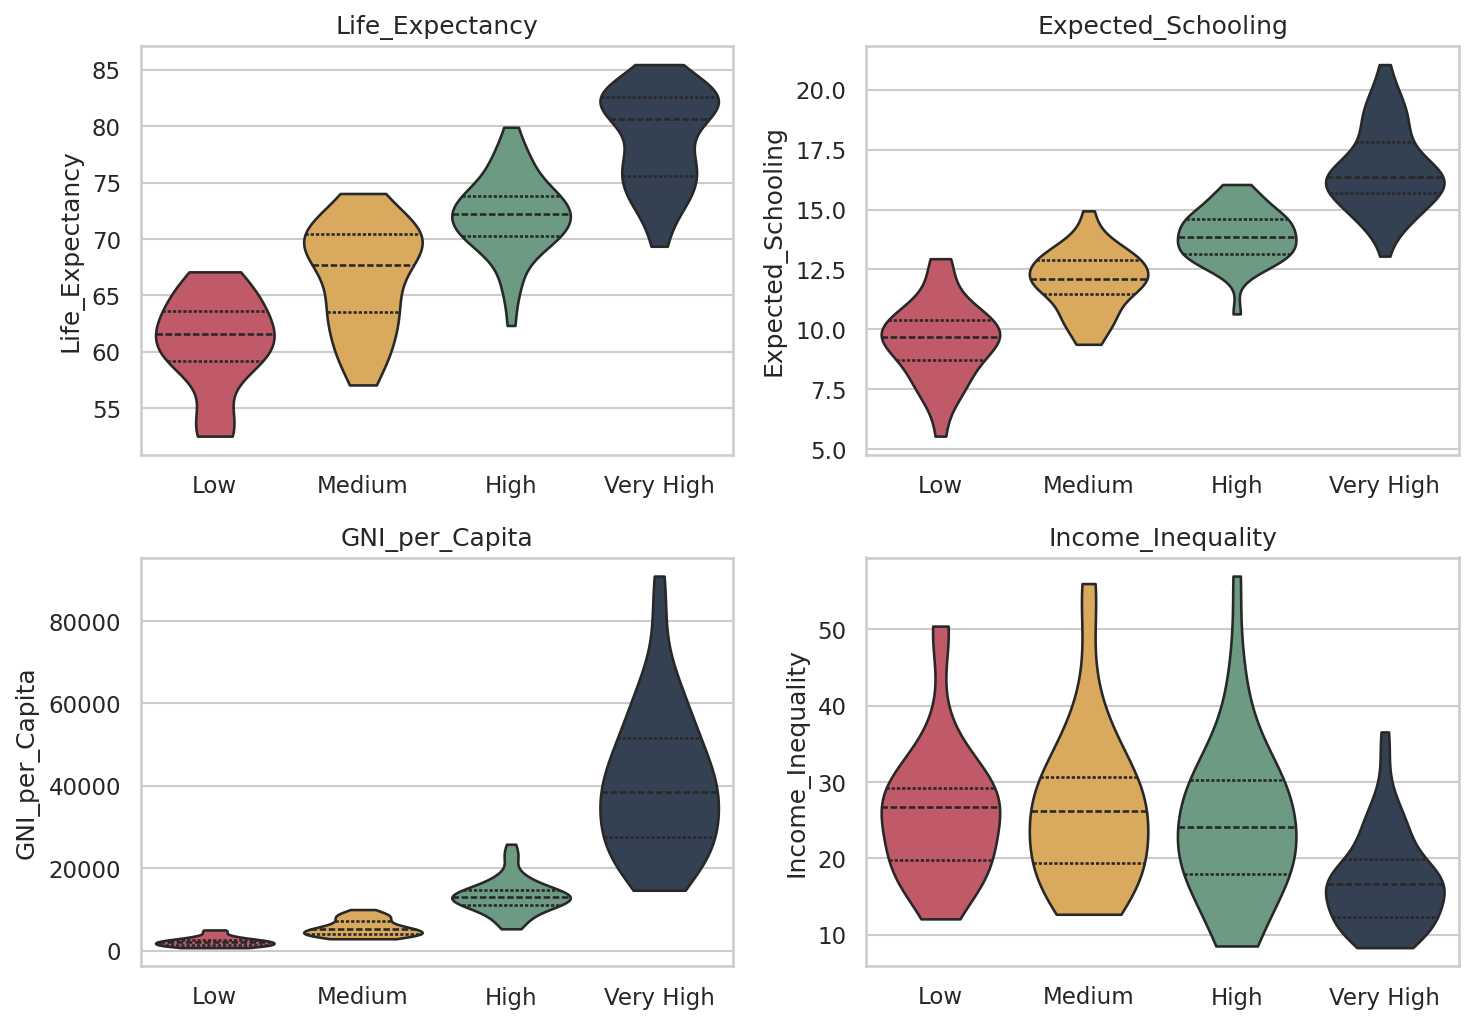

In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(10, 7))
for a, c in zip(ax.flatten(), feat):
    sns.violinplot(data=df, x="HDI_Group", y=c, order=order, palette=palette,
                   inner="quartile", cut=0, ax=a)
    a.set_xlabel(""); a.set_title(c)
plt.tight_layout(); plt.show()

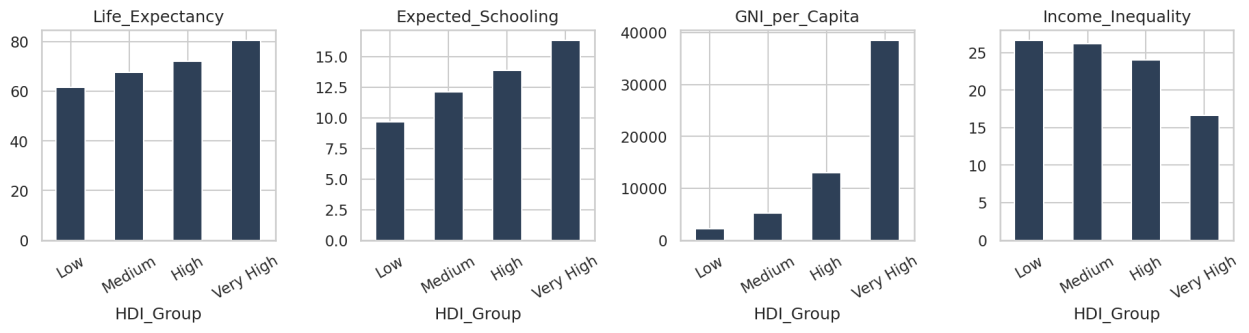

In [ ]:
med = df.groupby("HDI_Group")[feat].median().reindex(order)
med.plot(kind="bar", subplots=True, layout=(1, 4), figsize=(13, 3.6),
         legend=False, rot=30, color="#2e4057")
plt.tight_layout(); plt.show()

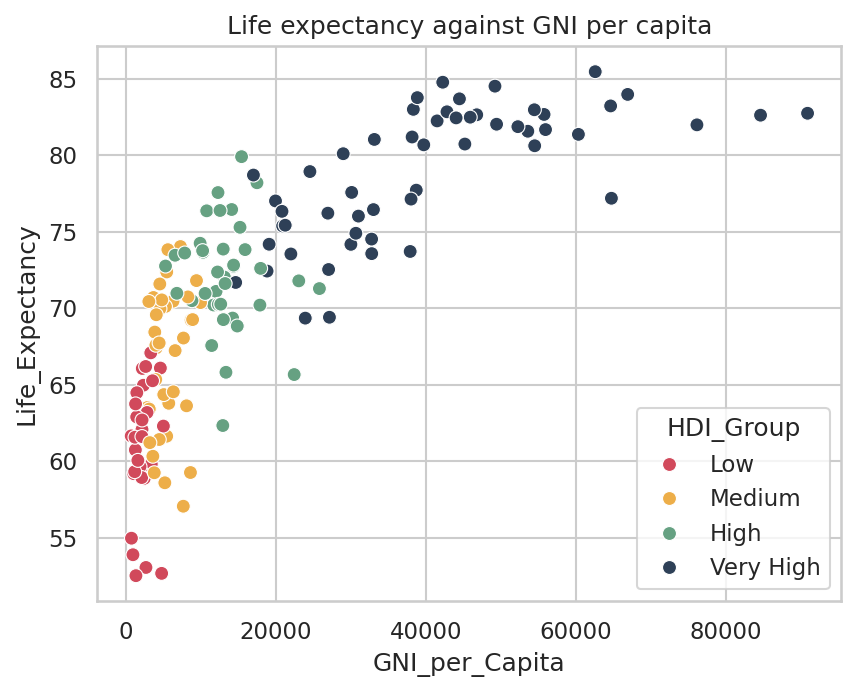

In [ ]:
sns.scatterplot(data=df, x="GNI_per_Capita", y="Life_Expectancy",
                hue="HDI_Group", hue_order=order, palette=palette, s=45)
plt.title("Life expectancy against GNI per capita"); plt.show()

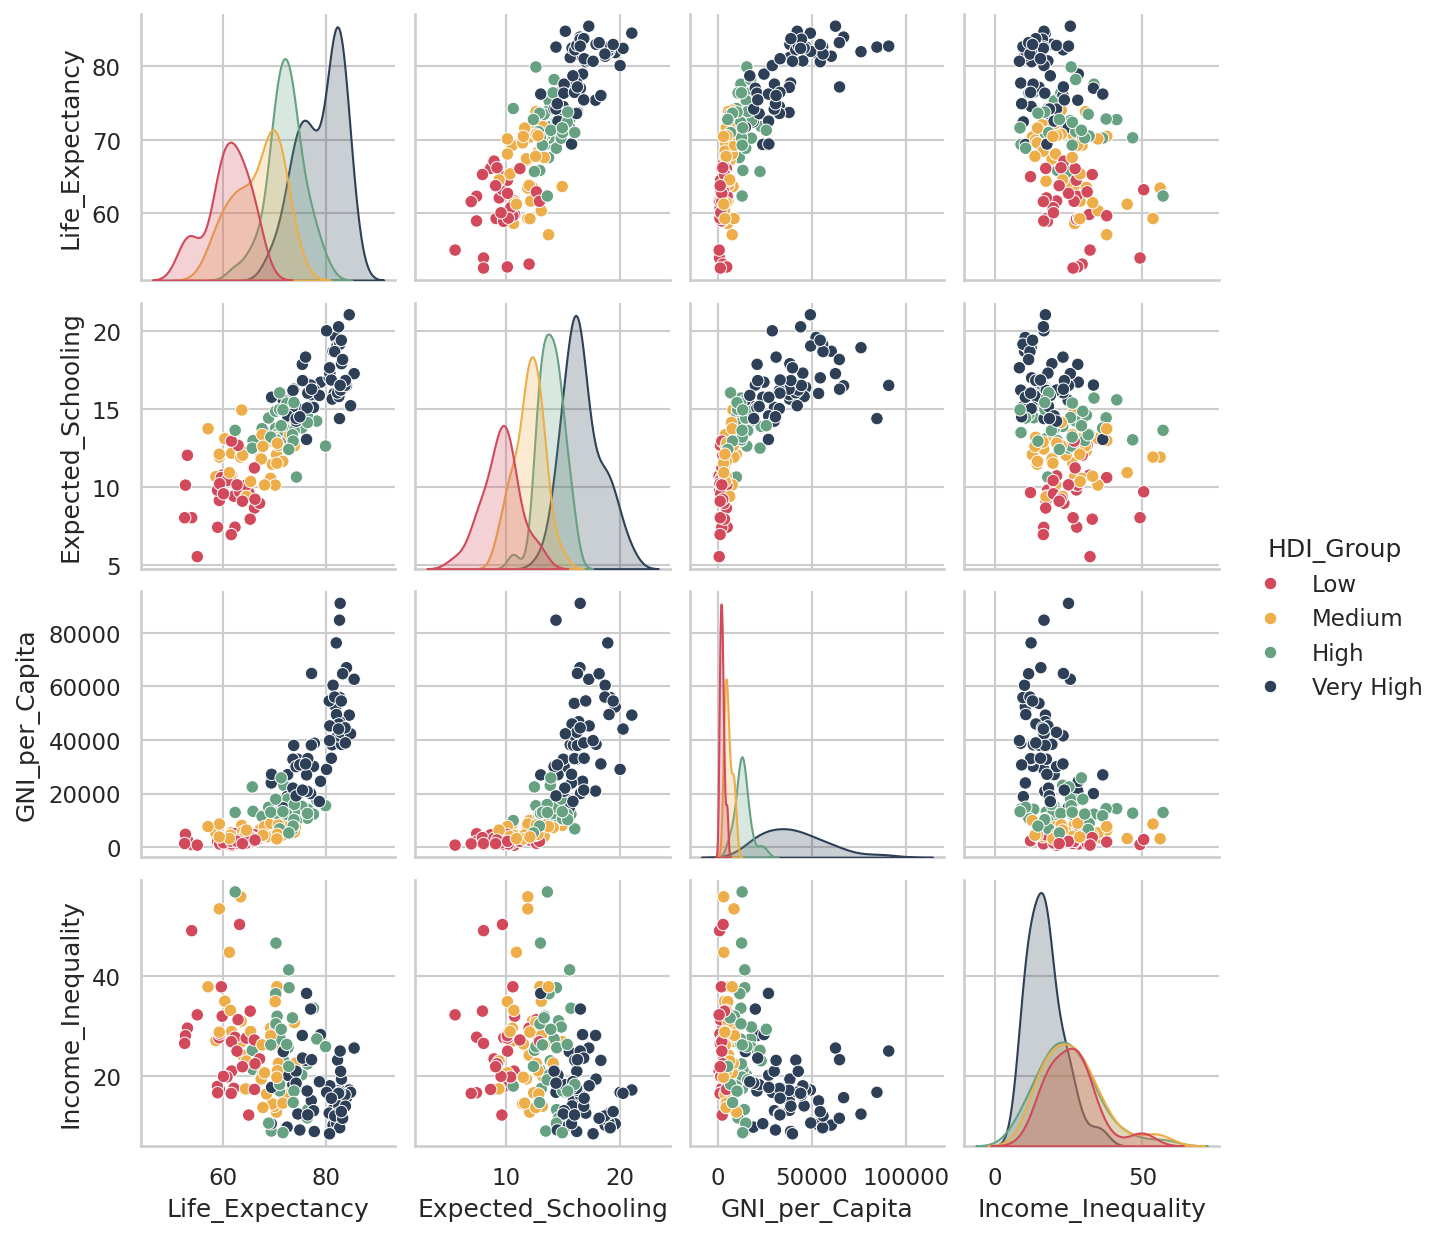

In [ ]:
sns.pairplot(df, vars=feat, hue="HDI_Group", hue_order=order,
             palette=palette, diag_kind="kde", height=2.1)
plt.show()

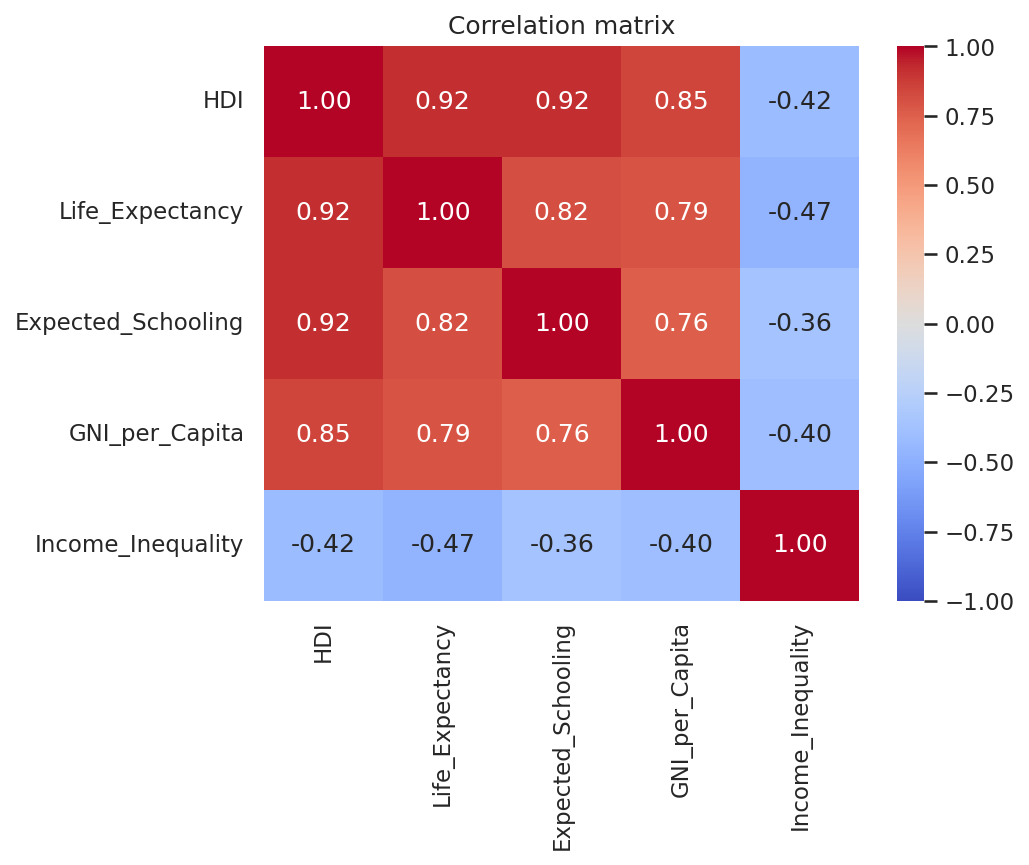

In [ ]:
corr = df[["HDI"] + feat].corr()
print(corr.round(2))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation matrix"); plt.show()

In [ ]:
Q1, Q3 = df[feat].quantile(.25), df[feat].quantile(.75)
IQR = Q3 - Q1
mask = (df[feat] < Q1 - 1.5 * IQR) | (df[feat] > Q3 + 1.5 * IQR)
print(pd.DataFrame({"Outliers": mask.sum(), "Percent": (mask.mean() * 100).round(2)}))
print()
print(df.loc[mask.any(axis=1), ["Country", "HDI_Group"] + feat].round(1).to_string(index=False))

In [ ]:
Z = df[feat].values
Z = (Z - Z.mean(0)) / Z.std(0)                    # standardise
vif = np.diag(np.linalg.inv(np.corrcoef(Z.T)))    # VIF = diagonal of inverse correlation matrix
print(pd.Series(vif, index=feat).round(2).sort_values(ascending=False))

## Step 4: Split and scale
Stratified 80/20 split (127 training and 32 test countries). The scaler is fitted on the training data only.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X, y = df[feat], df["HDI_Group"]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print("Training countries:", len(Xtr), "| Testing countries:", len(Xte))
print(pd.DataFrame({"train": ytr.value_counts(), "test": yte.value_counts()}).reindex(order))

scaler = StandardScaler().fit(Xtr)       # learn mean/std from training data only
Xtr_s = scaler.transform(Xtr)
Xte_s = scaler.transform(Xte)            # reuse the training mean/std
print(pd.DataFrame({"mean_before": Xtr.mean(), "std_before": Xtr.std(),
                    "mean_after": Xtr_s.mean(0), "std_after": Xtr_s.std(0, ddof=1)}).round(2) + 0.0)

## Step 5: Compare six classifiers
5-fold stratified cross-validation on the training set, against a majority-class baseline.

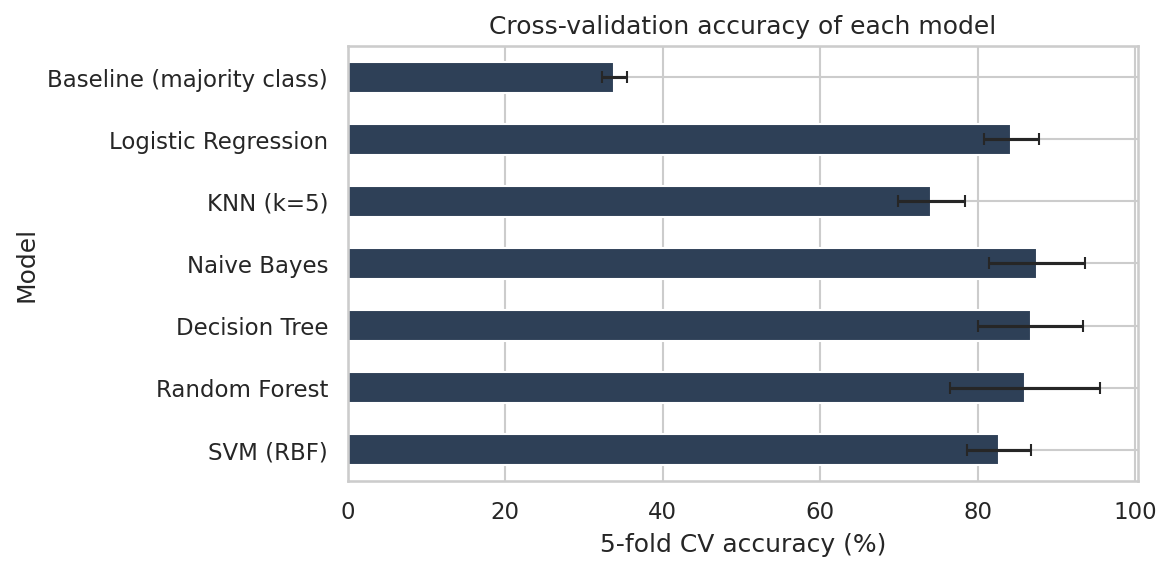

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

models = {
    "Baseline (majority class)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "KNN (k=5)": KNeighborsClassifier(5),
    "Naive Bayes": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "SVM (RBF)": SVC(),
}
cv = StratifiedKFold(5, shuffle=True, random_state=42)

rows = []
for name, m in models.items():
    pipe = make_pipeline(StandardScaler(), m)     # scaler is re-fitted inside every fold
    r = cross_validate(pipe, Xtr, ytr, cv=cv, scoring=["accuracy", "f1_macro"])
    rows.append([name, r["test_accuracy"].mean() * 100, r["test_accuracy"].std() * 100,
                 r["test_f1_macro"].mean() * 100])
cvtab = pd.DataFrame(rows, columns=["Model", "CV acc (%)", "CV std (%)", "CV macro-F1 (%)"]).round(2)
print(cvtab.to_string(index=False))

cvtab.set_index("Model")["CV acc (%)"].iloc[::-1].plot.barh(
    xerr=cvtab["CV std (%)"].values[::-1], color="#2e4057", figsize=(8, 4), capsize=3)
plt.xlabel("5-fold CV accuracy (%)"); plt.title("Cross-validation accuracy of each model")
plt.tight_layout(); plt.show()

## Step 6: Tune and check fairly
GridSearchCV for each model, then nested cross-validation so the scores are not optimistic.

In [ ]:
from sklearn.model_selection import GridSearchCV

grids = {
    "Logistic Regression": (LogisticRegression(max_iter=3000), {"logisticregression__C": [0.01, 0.1, 1, 10, 100]}),
    "KNN": (KNeighborsClassifier(), {"kneighborsclassifier__n_neighbors": list(range(1, 22, 2))}),
    "Naive Bayes": (GaussianNB(), {"gaussiannb__var_smoothing": [1e-9, 1e-5, 1e-2, 1e-1]}),
    "Decision Tree": (DecisionTreeClassifier(random_state=42),
                      {"decisiontreeclassifier__max_depth": [2, 3, 4, 5, None],
                       "decisiontreeclassifier__min_samples_leaf": [1, 2, 4]}),
    "Random Forest": (RandomForestClassifier(random_state=42),
                      {"randomforestclassifier__n_estimators": [100, 200],
                       "randomforestclassifier__max_depth": [None, 3, 5],
                       "randomforestclassifier__min_samples_leaf": [1, 2]}),
    "SVM (RBF)": (SVC(), {"svc__C": [0.1, 1, 10, 100], "svc__gamma": [0.01, 0.1, 1, "scale"]}),
}
best = {}
for name, (m, grid) in grids.items():
    gs = GridSearchCV(make_pipeline(StandardScaler(), m), grid, cv=cv, n_jobs=-1).fit(Xtr, ytr)
    best[name] = gs
    params = {k.split("__")[1]: v for k, v in gs.best_params_.items()}
    print(f"{name:20s} CV = {gs.best_score_ * 100:.2f}%   best = {params}")

In [ ]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score

inner = StratifiedKFold(5, shuffle=True, random_state=7)                         # tunes the hyperparameters
outer = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=3)         # scores the whole procedure
for name, (m, grid) in grids.items():
    gs = GridSearchCV(make_pipeline(StandardScaler(), m), grid, cv=inner, n_jobs=-1)
    s = cross_val_score(gs, X, y, cv=outer)
    print(f"{name:20s} nested CV = {s.mean() * 100:.2f}% +/- {s.std() * 100:.2f}")

## Step 7: Test the final model
The Random Forest was chosen from the validation results, then scored once on the 32 test countries.

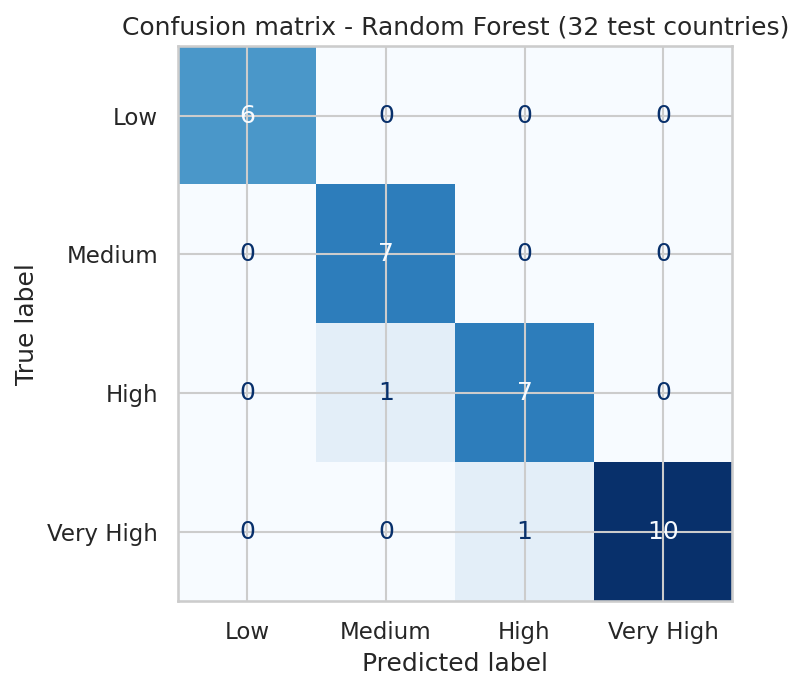

In [ ]:
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, matthews_corrcoef)

final = best["Random Forest"].best_estimator_
pred = final.predict(Xte)
print(classification_report(yte, pred, labels=order, digits=4))
cm = confusion_matrix(yte, pred, labels=order)
print(cm)
ConfusionMatrixDisplay(cm, display_labels=order).plot(cmap="Blues", colorbar=False)
plt.title("Confusion matrix - Random Forest (32 test countries)"); plt.show()
print("MCC:", round(matthews_corrcoef(yte, pred), 4))

n, k = len(yte), int((pred == yte).sum()); p = k / n; z = 1.96      # Wilson 95% interval
centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
print(f"Accuracy {p:.4f} ({k}/{n}), 95% CI {centre - half:.4f} to {centre + half:.4f}")

In [ ]:
wrong = pred != yte
err = Xte[wrong].copy()
err["Country"] = df.loc[err.index, "Country"]
err["HDI"] = df.loc[err.index, "HDI"]
err["True"] = yte[wrong]
err["Predicted"] = pred[wrong]
print(err[["Country", "HDI", "True", "Predicted"]].to_string(index=False))
print()
print(err[feat].round(1).assign(Country=err["Country"]).to_string(index=False))

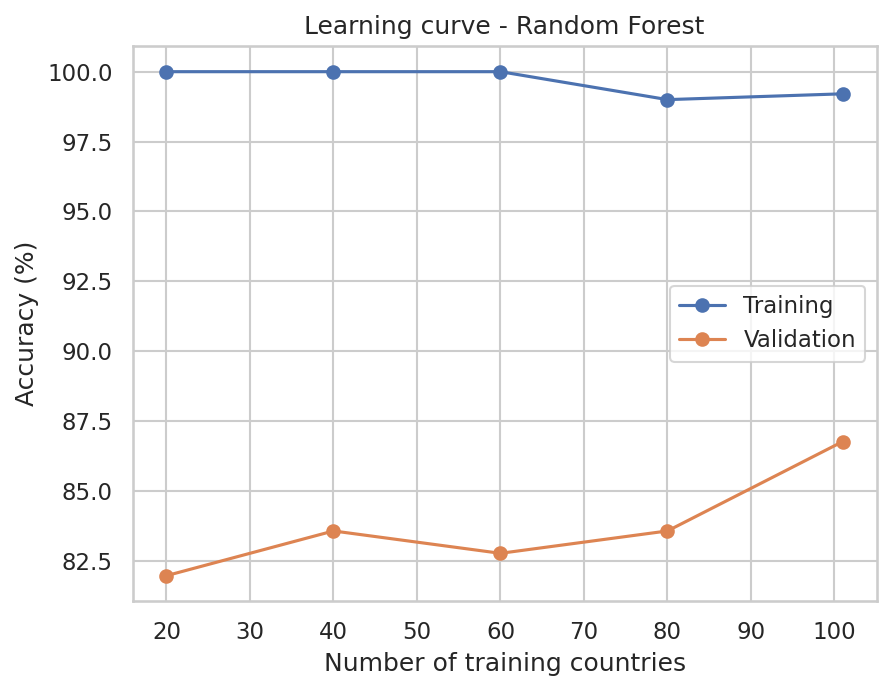

In [ ]:
from sklearn.model_selection import learning_curve

sizes, trs, vas = learning_curve(final, Xtr, ytr, cv=cv, train_sizes=np.linspace(0.2, 1, 5))
print(pd.DataFrame({"train_size": sizes, "train_acc": trs.mean(1).round(3),
                    "validation_acc": vas.mean(1).round(3)}).to_string(index=False))
plt.plot(sizes, trs.mean(1) * 100, "o-", label="Training")
plt.plot(sizes, vas.mean(1) * 100, "o-", label="Validation")
plt.xlabel("Number of training countries"); plt.ylabel("Accuracy (%)")
plt.title("Learning curve - Random Forest"); plt.legend(); plt.show()

## Step 8: Interpret the results

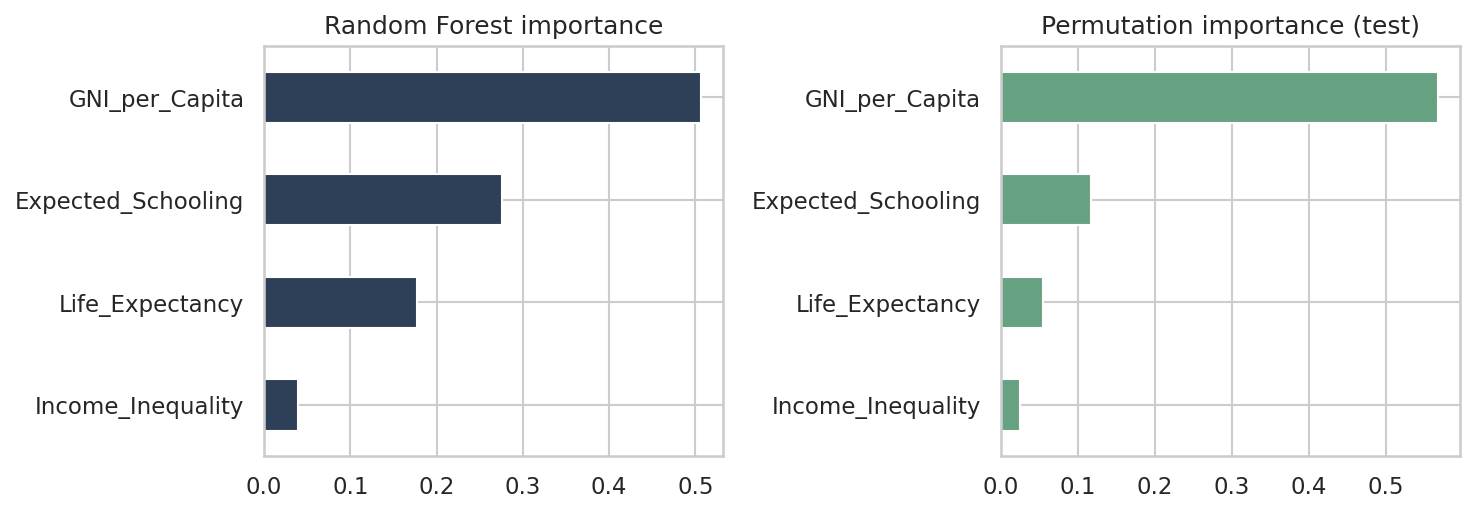

In [ ]:
from sklearn.inspection import permutation_importance

rf = final[-1]                                              # the forest inside the pipeline
imp = pd.Series(rf.feature_importances_, index=feat)        # 1. impurity-based importance
perm = permutation_importance(final, Xte, yte, n_repeats=30, random_state=42)
pimp = pd.Series(perm.importances_mean, index=feat)         # 2. permutation importance (test set)
print(pd.DataFrame({"RF importance": imp, "Permutation (test)": pimp})
        .round(3).sort_values("RF importance", ascending=False))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
imp.sort_values().plot.barh(ax=ax[0], color="#2e4057"); ax[0].set_title("Random Forest importance")
pimp.sort_values().plot.barh(ax=ax[1], color="#66a182"); ax[1].set_title("Permutation importance (test)")
plt.tight_layout(); plt.show()

In [ ]:
from sklearn.base import clone

sets = {"All 4 features": feat,
        "Drop Income_Inequality": [c for c in feat if c != "Income_Inequality"],
        "Drop Life_Expectancy": [c for c in feat if c != "Life_Expectancy"],
        "Drop Expected_Schooling": [c for c in feat if c != "Expected_Schooling"],
        "Drop GNI_per_Capita": [c for c in feat if c != "GNI_per_Capita"],
        "GNI + Schooling": ["GNI_per_Capita", "Expected_Schooling"],
        "GNI only": ["GNI_per_Capita"],
        "Life_Expectancy only": ["Life_Expectancy"]}
rows = []
for name, f in sets.items():
    m = clone(final)
    cvs = cross_val_score(m, Xtr[f], ytr, cv=cv).mean() * 100
    rows.append([name, len(f), round(cvs, 2), round(m.fit(Xtr[f], ytr).score(Xte[f], yte) * 100, 2)])
print(pd.DataFrame(rows, columns=["Feature set", "n", "CV acc (%)", "Test acc (%)"]).to_string(index=False))

## Results

- Cross-validated accuracy is about 87-88% (nested cross-validation: 87.6% for the Random Forest), against a 34% majority-class baseline.
- Test accuracy is 93.75% (30 of 32 countries), with a 95% confidence interval of 79.9% to 98.3%. The test set is small, so the cross-validated 87-88% is the more realistic figure.
- Both mistakes were between neighbouring groups, for countries within 0.015 of an HDI cut-off.
- GNI per capita is the most important feature. Life expectancy is mostly redundant given schooling and GNI. Income inequality adds a small amount of information.

**Limitations:** only 159 countries; life expectancy, schooling and GNI are inputs of the HDI formula, so high accuracy is partly expected; countries with missing data were dropped; one year only (2021).